In [1]:
import os
import warnings
warnings.filterwarnings("ignore")
!pip install kagglehub -q

import kagglehub
import pandas as pd
import os

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, classification_report, ConfusionMatrixDisplay,
    confusion_matrix, RocCurveDisplay
)

RANDOM_STATE = 42
pd.set_option("display.max_columns", 100)
sns.set_theme(style="whitegrid")

Load dataset

In [2]:

path = kagglehub.dataset_download("jessemostipak/hotel-booking-demand")

DATA_PATH = os.path.join(path, "hotel_bookings.csv")

df = pd.read_csv(DATA_PATH)

print("Dataset loaded successfully!")
print("Shape:", df.shape)
display(df.head())

Using Colab cache for faster access to the 'hotel-booking-demand' dataset.
Dataset loaded successfully!
Shape: (119390, 32)


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,meal,country,market_segment,distribution_channel,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,reserved_room_type,assigned_room_type,booking_changes,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,0.0,0,BB,PRT,Direct,Direct,0,0,0,C,C,3,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,0.0,0,BB,PRT,Direct,Direct,0,0,0,C,C,4,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,0.0,0,BB,GBR,Direct,Direct,0,0,0,A,C,0,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,0.0,0,BB,GBR,Corporate,Corporate,0,0,0,A,A,0,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,0.0,0,BB,GBR,Online TA,TA/TO,0,0,0,A,A,0,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03


In [3]:
print("Number of rows and columns:", df.shape)
print("\nData types and non-null counts:")
df.info()

Number of rows and columns: (119390, 32)

Data types and non-null counts:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 119390 entries, 0 to 119389
Data columns (total 32 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   hotel                           119390 non-null  object 
 1   is_canceled                     119390 non-null  int64  
 2   lead_time                       119390 non-null  int64  
 3   arrival_date_year               119390 non-null  int64  
 4   arrival_date_month              119390 non-null  object 
 5   arrival_date_week_number        119390 non-null  int64  
 6   arrival_date_day_of_month       119390 non-null  int64  
 7   stays_in_weekend_nights         119390 non-null  int64  
 8   stays_in_week_nights            119390 non-null  int64  
 9   adults                          119390 non-null  int64  
 10  children                        119386 non-null  float64
 11  babi

## Data quality
This step identifies data types, duplicate rows, and missing-value rates. Missing values are not filled before they are summarized

In [4]:
df.columns = df.columns.str.strip()

missing_summary = pd.DataFrame({
    "missing_count": df.isna().sum(),
    "missing_percent": (df.isna().mean() * 100).round(2),
    "dtype": df.dtypes.astype(str)
}).sort_values("missing_count", ascending=False)

display(missing_summary)


,missing_count,missing_percent,dtype
company,112593,94.31,float64
agent,16340,13.69,float64
country,488,0.41,object
children,4,0.00,float64
arrival_date_month,0,0.00,object
arrival_date_week_number,0,0.00,int64
hotel,0,0.00,object
is_canceled,0,0.00,int64
stays_in_weekend_nights,0,0.00,int64
arrival_date_day_of_month,0,0.00,int64


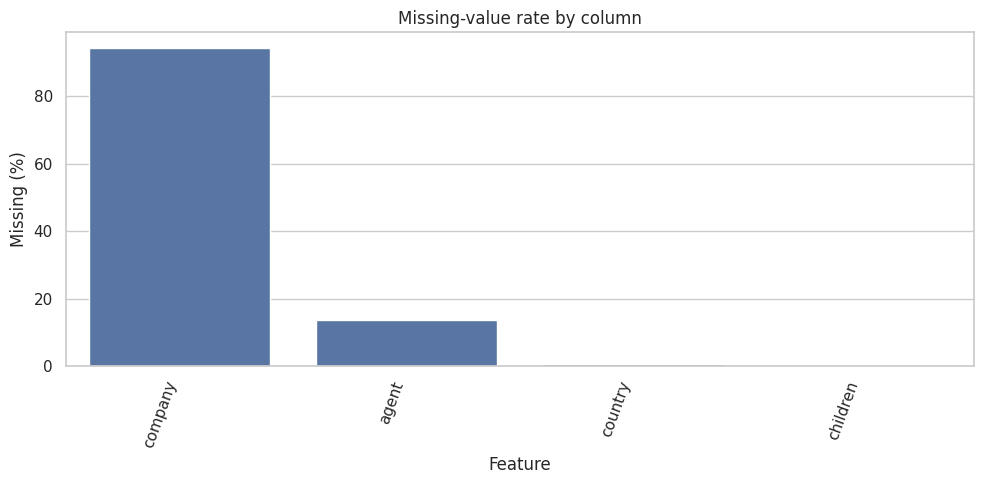

In [5]:
missing_plot = missing_summary[missing_summary["missing_count"] > 0].copy()

if not missing_plot.empty:
    plt.figure(figsize=(10, 5))
    sns.barplot(data=missing_plot.reset_index(), x="index", y="missing_percent")
    plt.title("Missing-value rate by column")
    plt.xlabel("Feature")
    plt.ylabel("Missing (%)")
    plt.xticks(rotation=70, ha="right")
    plt.tight_layout()
    plt.show()
else:
    print("No missing values were found in this dataset.")


#Duplicated rows

In [6]:
print(f"Fully duplicated rows: {df.duplicated().sum():,}")
df[df.duplicated(keep=False)].sort_values(
    by=df.columns.tolist()
).head(10)


Fully duplicated rows: 31,994


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,meal,country,market_segment,distribution_channel,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,reserved_room_type,assigned_room_type,booking_changes,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
40772,City Hotel,0,0,2015,August,32,7,0,2,2,0.0,0,BB,PRT,Direct,Direct,0,0,0,A,A,0,No Deposit,14.0,NaN,0,Transient,75.0,0,1,Check-Out,2015-08-09
40802,City Hotel,0,0,2015,August,32,7,0,2,2,0.0,0,BB,PRT,Direct,Direct,0,0,0,A,A,0,No Deposit,14.0,NaN,0,Transient,75.0,0,1,Check-Out,2015-08-09
40821,City Hotel,0,0,2015,August,32,8,0,1,2,0.0,0,SC,PRT,Online TA,TA/TO,0,0,0,A,A,0,No Deposit,9.0,NaN,0,Transient,89.0,0,1,Check-Out,2015-08-09
40838,City Hotel,0,0,2015,August,32,8,0,1,2,0.0,0,SC,PRT,Online TA,TA/TO,0,0,0,A,A,0,No Deposit,9.0,NaN,0,Transient,89.0,0,1,Check-Out,2015-08-09
76792,City Hotel,0,0,2015,August,33,10,1,0,2,0.0,0,SC,FRA,Online TA,TA/TO,0,0,0,A,A,0,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-08-11
76793,City Hotel,0,0,2015,August,33,10,1,0,2,0.0,0,SC,FRA,Online TA,TA/TO,0,0,0,A,A,0,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-08-11
76794,City Hotel,0,0,2015,August,33,10,1,0,2,0.0,0,SC,FRA,Online TA,TA/TO,0,0,0,A,A,0,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-08-11
41067,City Hotel,0,0,2015,August,33,11,0,1,1,0.0,0,BB,PRT,Corporate,Corporate,0,0,0,A,A,0,No Deposit,NaN,38.0,0,Transient-Party,88.0,0,0,Check-Out,2015-08-12
41073,City Hotel,0,0,2015,August,33,11,0,1,1,0.0,0,BB,PRT,Corporate,Corporate,0,0,0,A,A,0,No Deposit,NaN,38.0,0,Transient-Party,88.0,0,0,Check-Out,2015-08-12
41071,City Hotel,0,0,2015,August,33,11,0,1,2,0.0,0,BB,PRT,Direct,Direct,0,0,0,A,A,0,No Deposit,NaN,NaN,0,Transient,80.0,0,0,Check-Out,2015-08-12


## EDA — target-variable analysis

"is_canceled" is the target: "1" means that the booking was cancelled and "0" means that it was not cancelled.

,count,percentage
is_canceled,,
0,75166,62.96
1,44224,37.04


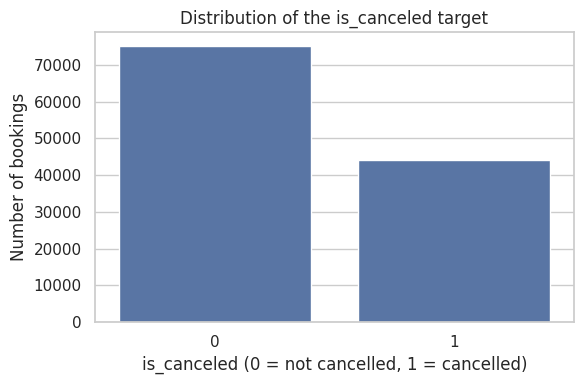

In [7]:
if "is_canceled" not in df.columns:
    raise ValueError("The dataset does not contain the 'is_canceled' column. Check the CSV file.")

target_counts = df["is_canceled"].value_counts(dropna=False).sort_index()
target_summary = pd.DataFrame({
    "count": target_counts,
    "percentage": (target_counts / len(df) * 100).round(2)
})
display(target_summary)

plt.figure(figsize=(6, 4))
sns.countplot(data=df, x="is_canceled")
plt.title("Distribution of the is_canceled target")
plt.xlabel("is_canceled (0 = not cancelled, 1 = cancelled)")
plt.ylabel("Number of bookings")
plt.tight_layout()
plt.show()


,cancellation_rate,bookings
hotel,,
City Hotel,41.73,79330
Resort Hotel,27.76,40060


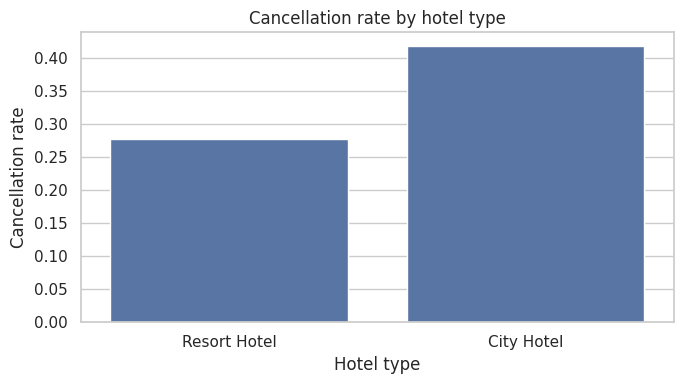

In [8]:
if "hotel" in df.columns:
    cancellation_by_hotel = (
        df.groupby("hotel", dropna=False)["is_canceled"]
          .agg(["mean", "count"])
          .rename(columns={"mean": "cancellation_rate", "count": "bookings"})
          .sort_values("cancellation_rate", ascending=False)
    )
    cancellation_by_hotel["cancellation_rate"] *= 100
    display(cancellation_by_hotel.round(2))

    plt.figure(figsize=(7, 4))
    sns.barplot(data=df, x="hotel", y="is_canceled", errorbar=None)
    plt.title("Cancellation rate by hotel type")
    plt.xlabel("Hotel type")
    plt.ylabel("Cancellation rate")
    plt.tight_layout()
    plt.show()


### EDA — numerical features and outliers

Outliers are identified with the IQR rule for descriptive purposes. They are not automatically removed because high values such as "lead_time" or "adr" may represent genuine bookings. Model performance should be evaluated before applying more aggressive treatment.


In [9]:
numeric_cols_eda = df.select_dtypes(include=np.number).columns.tolist()
display(df[numeric_cols_eda].describe().T)

,count,mean,std,min,25%,50%,75%,max
is_canceled,119390.0,0.370416,0.482918,0.00,0.00,0.000,1.0,1.0
lead_time,119390.0,104.011416,106.863097,0.00,18.00,69.000,160.0,737.0
arrival_date_year,119390.0,2016.156554,0.707476,2015.00,2016.00,2016.000,2017.0,2017.0
arrival_date_week_number,119390.0,27.165173,13.605138,1.00,16.00,28.000,38.0,53.0
arrival_date_day_of_month,119390.0,15.798241,8.780829,1.00,8.00,16.000,23.0,31.0
stays_in_weekend_nights,119390.0,0.927599,0.998613,0.00,0.00,1.000,2.0,19.0
stays_in_week_nights,119390.0,2.500302,1.908286,0.00,1.00,2.000,3.0,50.0
adults,119390.0,1.856403,0.579261,0.00,2.00,2.000,2.0,55.0
children,119386.0,0.103890,0.398561,0.00,0.00,0.000,0.0,10.0
babies,119390.0,0.007949,0.097436,0.00,0.00,0.000,0.0,10.0


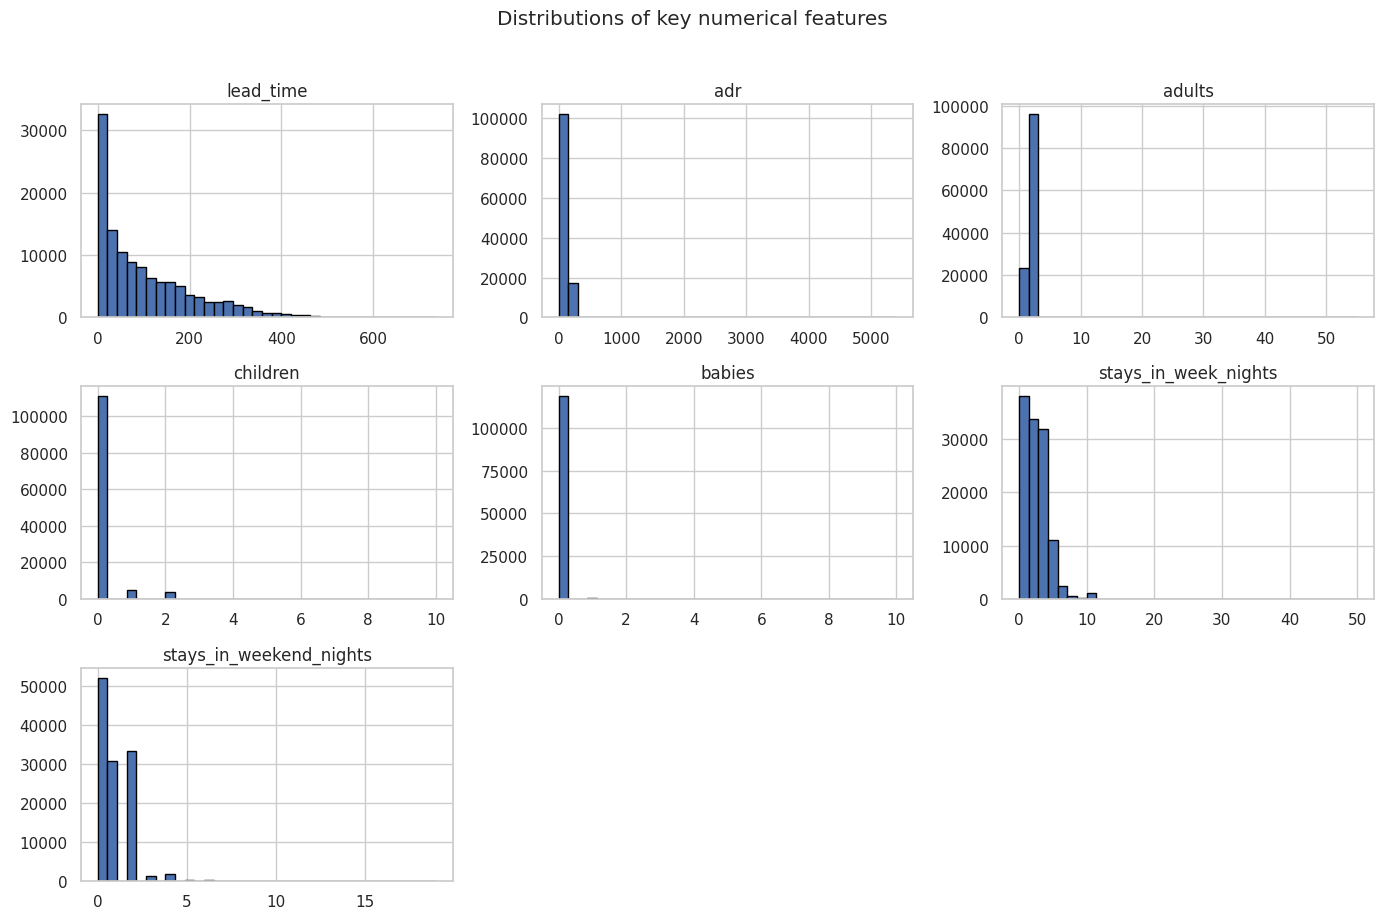

In [10]:
selected_numeric = [c for c in ["lead_time", "adr", "adults", "children",
                                "babies", "stays_in_week_nights",
                                "stays_in_weekend_nights"] if c in df.columns]

if selected_numeric:
    df[selected_numeric].hist(figsize=(14, 9), bins=35, edgecolor="black")
    plt.suptitle("Distributions of key numerical features", y=1.02)
    plt.tight_layout()
    plt.show()


In [11]:
outlier_rows = []
for col in numeric_cols_eda:
    series = df[col].dropna()
    if series.empty:
        continue
    q1, q3 = series.quantile([0.25, 0.75])
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    count = ((series < lower) | (series > upper)).sum()
    outlier_rows.append({
        "feature": col, "lower_bound": lower, "upper_bound": upper,
        "outlier_count": int(count),
        "outlier_percent": round(count / len(series) * 100, 2)
    })

outlier_summary = pd.DataFrame(outlier_rows).sort_values(
    "outlier_percent", ascending=False
)
display(outlier_summary)

,feature,lower_bound,upper_bound,outlier_count,outlier_percent
7,adults,2.000,2.000,29710,24.88
13,booking_changes,0.000,0.000,18076,15.14
8,children,0.000,0.000,8590,7.20
18,required_car_parking_spaces,0.000,0.000,7416,6.21
11,previous_cancellations,0.000,0.000,6484,5.43
10,is_repeated_guest,0.000,0.000,3810,3.19
17,adr,-15.775,211.065,3793,3.18
16,days_in_waiting_list,0.000,0.000,3698,3.10
12,previous_bookings_not_canceled,0.000,0.000,3620,3.03
6,stays_in_week_nights,-2.000,6.000,3354,2.81


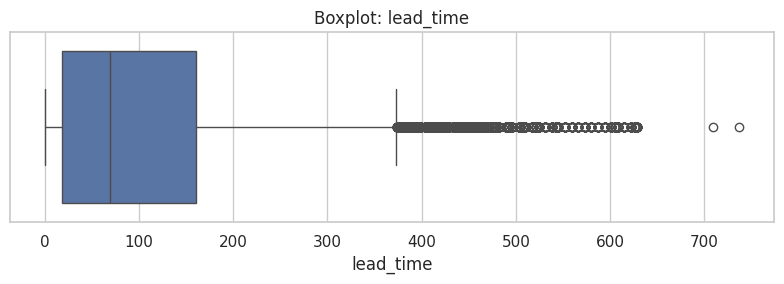

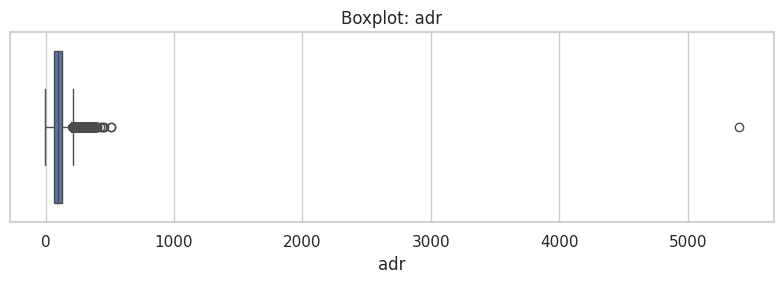

In [12]:
for col in [c for c in ["lead_time", "adr"] if c in df.columns]:
    plt.figure(figsize=(8, 3))
    sns.boxplot(x=df[col])
    plt.title(f"Boxplot: {col}")
    plt.tight_layout()
    plt.show()

## EDA — categorical features and the target

Use cancellation rates by group rather than booking counts alone, because group sizes differ.


In [13]:
categorical_cols_eda = df.select_dtypes(include=["object", "category"]).columns.tolist()
print("Number of categorical columns:", len(categorical_cols_eda))
print(categorical_cols_eda)

for col in [c for c in ["deposit_type", "market_segment", "customer_type",
                        "hotel", "meal"] if c in df.columns]:
    rate = (df.groupby(col, dropna=False)["is_canceled"]
              .agg(["mean", "count"])
              .rename(columns={"mean": "cancellation_rate", "count": "bookings"}))
    rate["cancellation_rate"] *= 100
    print(f"\nCancellation rate by {col}:")
    display(rate.sort_values("cancellation_rate", ascending=False).round(2))


Number of categorical columns: 12
['hotel', 'arrival_date_month', 'meal', 'country', 'market_segment', 'distribution_channel', 'reserved_room_type', 'assigned_room_type', 'deposit_type', 'customer_type', 'reservation_status', 'reservation_status_date']

Cancellation rate by deposit_type:


,cancellation_rate,bookings
deposit_type,,
Non Refund,99.36,14587
No Deposit,28.38,104641
Refundable,22.22,162



Cancellation rate by market_segment:


,cancellation_rate,bookings
market_segment,,
Undefined,100.00,2
Groups,61.06,19811
Online TA,36.72,56477
Offline TA/TO,34.32,24219
Aviation,21.94,237
Corporate,18.73,5295
Direct,15.34,12606
Complementary,13.06,743



Cancellation rate by customer_type:


,cancellation_rate,bookings
customer_type,,
Transient,40.75,89613
Contract,30.96,4076
Transient-Party,25.43,25124
Group,10.23,577



Cancellation rate by hotel:


,cancellation_rate,bookings
hotel,,
City Hotel,41.73,79330
Resort Hotel,27.76,40060



Cancellation rate by meal:


,cancellation_rate,bookings
meal,,
FB,59.90,798
BB,37.38,92310
SC,37.24,10650
HB,34.46,14463
Undefined,24.47,1169


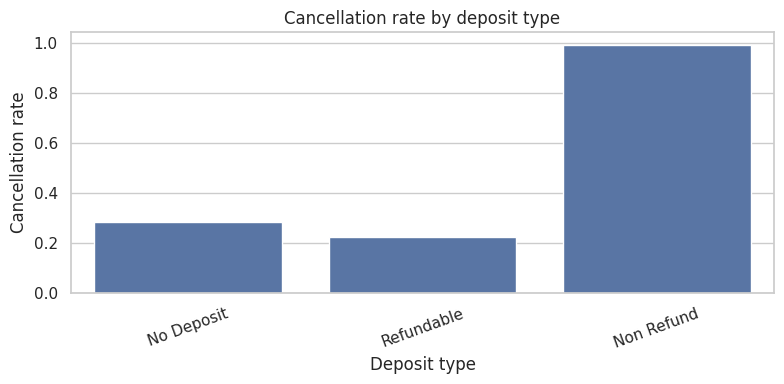

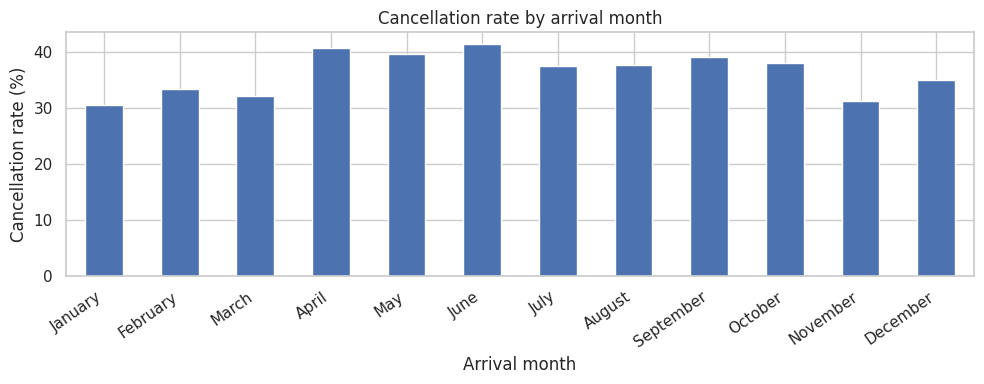

In [14]:
if "deposit_type" in df.columns:
    plt.figure(figsize=(8, 4))
    sns.barplot(data=df, x="deposit_type", y="is_canceled", errorbar=None)
    plt.title("Cancellation rate by deposit type")
    plt.xlabel("Deposit type")
    plt.ylabel("Cancellation rate")
    plt.xticks(rotation=20)
    plt.tight_layout()
    plt.show()

if "arrival_date_month" in df.columns:
    month_order = ["January", "February", "March", "April", "May", "June",
                   "July", "August", "September", "October", "November", "December"]
    observed = df["arrival_date_month"].dropna().unique().tolist()
    order = [m for m in month_order if m in observed] or sorted(observed)
    monthly_rate = (df.groupby("arrival_date_month")["is_canceled"].mean() * 100)
    monthly_rate = monthly_rate.reindex(order).dropna()

    plt.figure(figsize=(10, 4))
    monthly_rate.plot(kind="bar")
    plt.title("Cancellation rate by arrival month")
    plt.xlabel("Arrival month")
    plt.ylabel("Cancellation rate (%)")
    plt.xticks(rotation=35, ha="right")
    plt.tight_layout()
    plt.show()


## Data cleaning and feature definition

### Key decisions

- Remove fully duplicated rows after reporting their count.
- Remove "reservation_status" and "reservation_status_date" because they can leak the booking outcome.
- Do not include the target "is_canceled" among the features.
- Treat "agent" and "company" as categorical identifiers even though they are stored as numbers; they should not be scaled as continuous quantities.
- Impute missing values inside the pipeline, fitted on the training set only, to avoid leakage.


In [15]:
df_model = df.copy()

# 1. Clean column names
df_model.columns = df_model.columns.str.strip()

# 2. Check fully duplicated rows
print(f"Fully duplicated rows: {df_model.duplicated().sum():,}")

display(
    df_model[df_model.duplicated(keep=False)]
    .sort_values(by=df_model.columns.tolist())
    .head(10)
)

# 3. Remove duplicate rows
before = len(df_model)
df_model = df_model.drop_duplicates(keep="first").copy()
after = len(df_model)

print(f"\nRows before deduplication: {before:,}")
print(f"Duplicate rows removed: {before - after:,}")
print(f"Rows after deduplication: {after:,}")
print(f"Remaining duplicates: {df_model.duplicated().sum():,}")

# 4. Check whether agent contains 0 before imputation
if "agent" in df_model.columns:
    print(
        f"\nNumber of zeros in agent before imputation: "
        f"{(df_model['agent'] == 0).sum():,}"
    )

# 5. Handle missing values
# Drop company due to its high percentage of missing values
if "company" in df_model.columns:
    df_model = df_model.drop(columns=["company"])

# Fill missing agent values with 0 and convert to integer
if "agent" in df_model.columns:
    df_model["agent"] = df_model["agent"].fillna(0).astype("int64")

# Fill missing country values with "Unknown"
if "country" in df_model.columns:
    df_model["country"] = df_model["country"].fillna("Unknown")

# Keep missing numerical values (e.g., children) as NaN here.
# They will be imputed inside the ML pipeline using training-set statistics only.

# 6. Display missing-value summary after treatment
missing_summary = pd.DataFrame({
    "missing_count": df_model.isna().sum(),
    "missing_percent": (df_model.isna().mean() * 100).round(2),
    "dtype": df_model.dtypes.astype(str)
}).sort_values("missing_count", ascending=False)

display(missing_summary)

# 7. Remove leakage columns
leakage_cols = [
    c for c in ["reservation_status", "reservation_status_date"]
    if c in df_model.columns
]
df_model = df_model.drop(columns=leakage_cols)

# 8. Validate the target column
target_col = "is_canceled"

if target_col not in df_model.columns:
    raise ValueError("The target column is_canceled was not found.")

# Remove rows with missing targets
df_model = df_model.dropna(subset=[target_col]).copy()
df_model[target_col] = df_model[target_col].astype(int)




Fully duplicated rows: 31,994


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,meal,country,market_segment,distribution_channel,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,reserved_room_type,assigned_room_type,booking_changes,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
40772,City Hotel,0,0,2015,August,32,7,0,2,2,0.0,0,BB,PRT,Direct,Direct,0,0,0,A,A,0,No Deposit,14.0,NaN,0,Transient,75.0,0,1,Check-Out,2015-08-09
40802,City Hotel,0,0,2015,August,32,7,0,2,2,0.0,0,BB,PRT,Direct,Direct,0,0,0,A,A,0,No Deposit,14.0,NaN,0,Transient,75.0,0,1,Check-Out,2015-08-09
40821,City Hotel,0,0,2015,August,32,8,0,1,2,0.0,0,SC,PRT,Online TA,TA/TO,0,0,0,A,A,0,No Deposit,9.0,NaN,0,Transient,89.0,0,1,Check-Out,2015-08-09
40838,City Hotel,0,0,2015,August,32,8,0,1,2,0.0,0,SC,PRT,Online TA,TA/TO,0,0,0,A,A,0,No Deposit,9.0,NaN,0,Transient,89.0,0,1,Check-Out,2015-08-09
76792,City Hotel,0,0,2015,August,33,10,1,0,2,0.0,0,SC,FRA,Online TA,TA/TO,0,0,0,A,A,0,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-08-11
76793,City Hotel,0,0,2015,August,33,10,1,0,2,0.0,0,SC,FRA,Online TA,TA/TO,0,0,0,A,A,0,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-08-11
76794,City Hotel,0,0,2015,August,33,10,1,0,2,0.0,0,SC,FRA,Online TA,TA/TO,0,0,0,A,A,0,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-08-11
41067,City Hotel,0,0,2015,August,33,11,0,1,1,0.0,0,BB,PRT,Corporate,Corporate,0,0,0,A,A,0,No Deposit,NaN,38.0,0,Transient-Party,88.0,0,0,Check-Out,2015-08-12
41073,City Hotel,0,0,2015,August,33,11,0,1,1,0.0,0,BB,PRT,Corporate,Corporate,0,0,0,A,A,0,No Deposit,NaN,38.0,0,Transient-Party,88.0,0,0,Check-Out,2015-08-12
41071,City Hotel,0,0,2015,August,33,11,0,1,2,0.0,0,BB,PRT,Direct,Direct,0,0,0,A,A,0,No Deposit,NaN,NaN,0,Transient,80.0,0,0,Check-Out,2015-08-12



Rows before deduplication: 119,390
Duplicate rows removed: 31,994
Rows after deduplication: 87,396
Remaining duplicates: 0

Number of zeros in agent before imputation: 0


,missing_count,missing_percent,dtype
children,4,0.0,float64
is_canceled,0,0.0,int64
hotel,0,0.0,object
arrival_date_year,0,0.0,int64
arrival_date_month,0,0.0,object
arrival_date_week_number,0,0.0,int64
lead_time,0,0.0,int64
arrival_date_day_of_month,0,0.0,int64
stays_in_weekend_nights,0,0.0,int64
stays_in_week_nights,0,0.0,int64


In [16]:
# 9. Check data validity
if "children" in df_model.columns:
    print("Negative children values:",
          (df_model["children"] < 0).sum())

if "adr" in df_model.columns:
    print("Negative ADR values:",
          (df_model["adr"] < 0).sum())

if "is_canceled" in df_model.columns:
    print("Invalid is_canceled values:",
          (~df_model["is_canceled"].isin([0, 1])).sum())

if "agent" in df_model.columns:
    print("Agent values equal to 0:",
          (df_model["agent"] == 0).sum())

if "country" in df_model.columns:
    print("Unknown country values:",
          (df_model["country"] == "Unknown").sum())




# 9. Separate features and target
X = df_model.drop(columns=[target_col])
y = df_model[target_col]


Negative children values: 0
Negative ADR values: 1
Invalid is_canceled values: 0
Agent values equal to 0: 12193
Unknown country values: 452


In [17]:
# Inspect rows with negative ADR
if "adr" in df_model.columns:
    display(df_model[df_model["adr"] < 0])

    # Replace invalid negative ADR values with NaN.
    # Do not calculate the median here: the ML pipeline will fit its imputer
    # on X_train only, avoiding information leakage from the test set.
    df_model.loc[df_model["adr"] < 0, "adr"] = np.nan

    print("Negative ADR values:", (df_model["adr"] < 0).sum())
    print("Missing ADR values (to be imputed in pipeline):", df_model["adr"].isna().sum())
else:
    print("Column 'adr' was not found; skipping ADR validation.")


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,meal,country,market_segment,distribution_channel,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,reserved_room_type,assigned_room_type,booking_changes,deposit_type,agent,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests
14969,Resort Hotel,0,195,2017,March,10,5,4,6,2,0.0,0,BB,GBR,Groups,Direct,1,0,2,A,H,2,No Deposit,273,0,Transient-Party,-6.38,0,0


Negative ADR values: 0
Missing ADR values (to be imputed in pipeline): 1


### Post-cleaning EDA

=== Missing Values After Cleaning ===


,missing_count,missing_percent,dtype
children,4,0.0,float64
adr,1,0.0,float64



=== Duplicate Check ===
Fully duplicated rows: 266

=== Dataset Overview ===
Dataset shape: (87396, 29)
<class 'pandas.core.frame.DataFrame'>
Index: 87396 entries, 0 to 119389
Data columns (total 29 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   hotel                           87396 non-null  object 
 1   is_canceled                     87396 non-null  int64  
 2   lead_time                       87396 non-null  int64  
 3   arrival_date_year               87396 non-null  int64  
 4   arrival_date_month              87396 non-null  object 
 5   arrival_date_week_number        87396 non-null  int64  
 6   arrival_date_day_of_month       87396 non-null  int64  
 7   stays_in_weekend_nights         87396 non-null  int64  
 8   stays_in_week_nights            87396 non-null  int64  
 9   adults                          87396 non-null  int64  
 10  children                        87392 non-null  float

,count,mean,std,min,25%,50%,75%,max
is_canceled,87396.0,0.274898,0.446466,0.0,0.0,0.0,1.0,1.0
lead_time,87396.0,79.891368,86.052325,0.0,11.0,49.0,125.0,737.0
arrival_date_year,87396.0,2016.210296,0.686102,2015.0,2016.0,2016.0,2017.0,2017.0
arrival_date_week_number,87396.0,26.838334,13.674572,1.0,16.0,27.0,37.0,53.0
arrival_date_day_of_month,87396.0,15.815541,8.835146,1.0,8.0,16.0,23.0,31.0
stays_in_weekend_nights,87396.0,1.005263,1.031921,0.0,0.0,1.0,2.0,19.0
stays_in_week_nights,87396.0,2.625395,2.053584,0.0,1.0,2.0,4.0,50.0
adults,87396.0,1.875795,0.626500,0.0,2.0,2.0,2.0,55.0
children,87392.0,0.138640,0.455881,0.0,0.0,0.0,0.0,10.0
babies,87396.0,0.010824,0.113597,0.0,0.0,0.0,0.0,10.0



=== Categorical Features Summary ===


,count,unique,top,freq
hotel,87396,2,City Hotel,53428
arrival_date_month,87396,12,August,11257
meal,87396,5,BB,67978
country,87396,178,PRT,27453
market_segment,87396,8,Online TA,51618
distribution_channel,87396,5,TA/TO,69141
reserved_room_type,87396,10,A,56552
assigned_room_type,87396,12,A,46313
deposit_type,87396,3,No Deposit,86251
customer_type,87396,4,Transient,71986


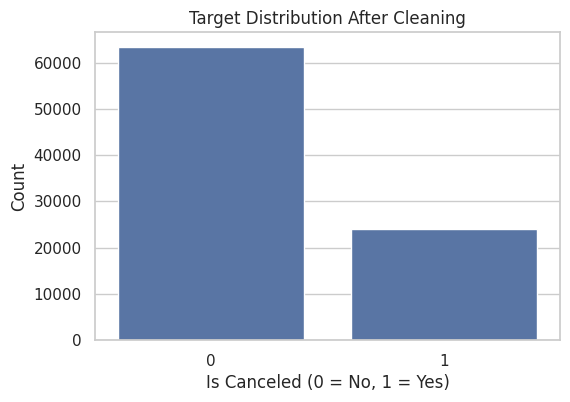


Target proportions:


,proportion
is_canceled,
0,0.725102
1,0.274898



=== Data Validity Checks ===
Negative children values: 0
Negative ADR values: 0
Invalid is_canceled values: 0
Agent values equal to 0: 12193
Unknown country values: 452


In [18]:

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Check missing values
print("=== Missing Values After Cleaning ===")

missing_summary = pd.DataFrame({
    "missing_count": df_model.isna().sum(),
    "missing_percent": (df_model.isna().mean() * 100).round(2),
    "dtype": df_model.dtypes.astype(str)
}).sort_values("missing_count", ascending=False)

display(missing_summary[missing_summary["missing_count"] > 0])

# 2. Check duplicate rows
print("\n=== Duplicate Check ===")
print(f"Fully duplicated rows: {df_model.duplicated().sum():,}")

# 3. Check dataset shape and data types
print("\n=== Dataset Overview ===")
print(f"Dataset shape: {df_model.shape}")
df_model.info()

# 4. Numerical features summary
print("\n=== Numerical Features Summary ===")
display(df_model.describe().T)

# 5. Categorical features summary
print("\n=== Categorical Features Summary ===")
display(df_model.describe(include=["object", "category", "string"]).T)

# 6. Visualize target distribution
if "is_canceled" in df_model.columns:
    plt.figure(figsize=(6, 4))
    sns.countplot(data=df_model, x="is_canceled")
    plt.title("Target Distribution After Cleaning")
    plt.xlabel("Is Canceled (0 = No, 1 = Yes)")
    plt.ylabel("Count")
    plt.show()

    print("\nTarget proportions:")
    display(
        df_model["is_canceled"]
        .value_counts(normalize=True)
        .sort_index()
        .rename("proportion")
        .to_frame()
    )

# 7. Check data validity
print("\n=== Data Validity Checks ===")

if "children" in df_model.columns:
    print("Negative children values:",
          (df_model["children"] < 0).sum())

if "adr" in df_model.columns:
    print("Negative ADR values:",
          (df_model["adr"] < 0).sum())

if "is_canceled" in df_model.columns:
    print("Invalid is_canceled values:",
          (~df_model["is_canceled"].isin([0, 1])).sum())

if "agent" in df_model.columns:
    print("Agent values equal to 0:",
          (df_model["agent"] == 0).sum())

if "country" in df_model.columns:
    print("Unknown country values:",
          (df_model["country"] == "Unknown").sum())


# Machine Learning — Hotel Booking Cancellation Prediction

Mục tiêu: huấn luyện mô hình Random Forest để dự đoán một booking có bị hủy hay không (`is_canceled`).

Pipeline gồm:
1. Tạo lại `X` và `y` từ dữ liệu đã làm sạch.
2. Chia train/test theo tỷ lệ 80/20 và giữ tỷ lệ nhãn bằng `stratify`.
3. Impute missing values và One-Hot Encode biến phân loại bên trong pipeline.
4. Huấn luyện Random Forest và đánh giá trên tập test.
5. Xem các đặc trưng có ảnh hưởng lớn đến dự đoán.

**Lưu ý:** `reservation_status` và `reservation_status_date` đã bị loại ở bước trước vì chứa thông tin sau kết quả booking. Nếu mục tiêu thực tế là dự đoán ngay tại thời điểm khách vừa đặt phòng, cần rà soát thêm các biến có thể chỉ được biết sau thời điểm đặt (ví dụ `assigned_room_type`, `booking_changes` hoặc `days_in_waiting_list`) và loại chúng khỏi `X` trước khi train.

Numerical features are standardized using StandardScaler (mean 0, standard deviation 1). The scaler is fitted on the training set only. Categorical features are One-Hot Encoded and are not scaled.


In [19]:
# 1. Rebuild features and target AFTER all cleaning steps

target_col = "is_canceled"

# Ensure the target exists and contains only the expected binary labels.
if target_col not in df_model.columns:
    raise ValueError(f"Target column '{target_col}' was not found.")

df_model = df_model.dropna(subset=[target_col]).copy()
df_model[target_col] = df_model[target_col].astype(int)

invalid_labels = set(df_model[target_col].unique()) - {0, 1}
if invalid_labels:
    raise ValueError(f"Unexpected target labels: {invalid_labels}")

X = df_model.drop(columns=[target_col]).copy()
y = df_model[target_col].copy()

# 'agent' is an identifier, not a continuous numeric measurement.
# Convert it to string so it is handled as a categorical feature.
if "agent" in X.columns:
    X["agent"] = X["agent"].fillna(0).astype(str)

# Detect feature types.
numeric_features = X.select_dtypes(include=["number"]).columns.tolist()
categorical_features = X.select_dtypes(
    include=["object", "category", "string"]
).columns.tolist()

print("Feature matrix:", X.shape)
print("Target distribution:")
display(
    y.value_counts()
     .sort_index()
     .rename(index={0: "Not canceled (0)", 1: "Canceled (1)"})
     .to_frame("count")
)
print(f"Numeric features ({len(numeric_features)}):", numeric_features)
print(f"Categorical features ({len(categorical_features)}):", categorical_features)

if not numeric_features and not categorical_features:
    raise ValueError("No usable input features were detected.")


Feature matrix: (87396, 28)
Target distribution:


,count
is_canceled,
Not canceled (0),63371
Canceled (1),24025


Numeric features (17): ['lead_time', 'arrival_date_year', 'arrival_date_week_number', 'arrival_date_day_of_month', 'stays_in_weekend_nights', 'stays_in_week_nights', 'adults', 'children', 'babies', 'is_repeated_guest', 'previous_cancellations', 'previous_bookings_not_canceled', 'booking_changes', 'days_in_waiting_list', 'adr', 'required_car_parking_spaces', 'total_of_special_requests']
Categorical features (11): ['hotel', 'arrival_date_month', 'meal', 'country', 'market_segment', 'distribution_channel', 'reserved_room_type', 'assigned_room_type', 'deposit_type', 'agent', 'customer_type']


In [20]:
# 2. Train-test split (80% train, 20% test)

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

print("Training set:", X_train.shape)
print("Test set:", X_test.shape)
print("\nTraining target proportions:")
display(y_train.value_counts(normalize=True).sort_index().rename("proportion").to_frame())
print("\nTest target proportions:")
display(y_test.value_counts(normalize=True).sort_index().rename("proportion").to_frame())


Training set: (69916, 28)
Test set: (17480, 28)

Training target proportions:


,proportion
is_canceled,
0,0.725099
1,0.274901



Test target proportions:


,proportion
is_canceled,
0,0.725114
1,0.274886


## Train/Test Data Visualization

Phần này trực quan hóa dữ liệu sau khi chia thành `X_train`, `X_test`, `y_train` và `y_test`. Các biểu đồ sử dụng **giá trị gốc trước preprocessing** để có thể diễn giải ý nghĩa của feature; không fit scaler/encoder trên tập test.



Class distribution in Train and Test sets:


Count          Percentage       
Dataset              Test    Train       Test  Train
Class                                               
Canceled (1)       4805.0  19220.0      27.49  27.49
Not canceled (0)  12675.0  50696.0      72.51  72.51

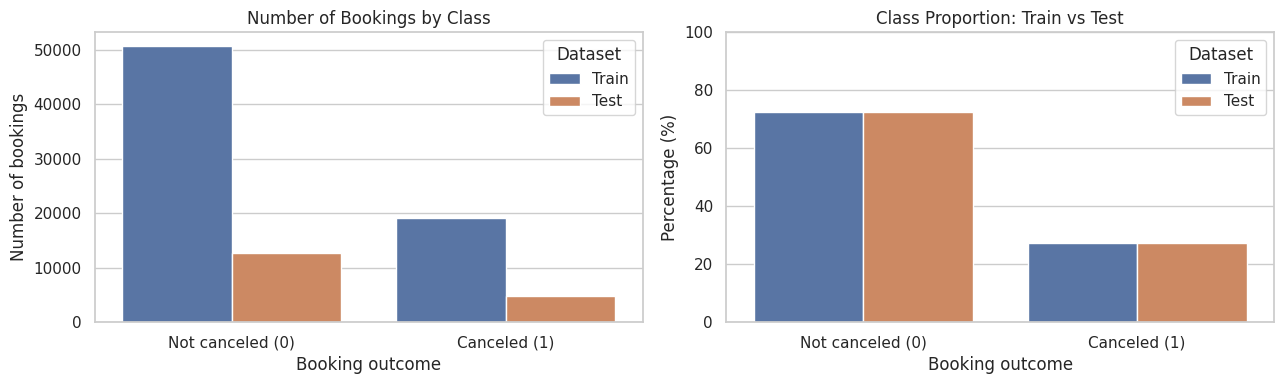

Interpretation: with stratified splitting, the class percentages in Train and Test should be close.


In [21]:
# 1. Compare target class distribution in Train and Test
class_labels = {0: "Not canceled (0)", 1: "Canceled (1)"}

class_balance_rows = []
for split_name, target in [("Train", y_train), ("Test", y_test)]:
    counts = target.value_counts().reindex([0, 1], fill_value=0)
    total = counts.sum()
    for class_value, count in counts.items():
        class_balance_rows.append({
            "Dataset": split_name,
            "Class": class_labels[class_value],
            "Count": int(count),
            "Percentage": count / total * 100 if total else 0
        })

class_balance_df = pd.DataFrame(class_balance_rows)
print("Class distribution in Train and Test sets:")
display(class_balance_df.pivot(index="Class", columns="Dataset", values=["Count", "Percentage"]).round(2))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.barplot(data=class_balance_df, x="Class", y="Count", hue="Dataset", ax=axes[0])
axes[0].set_title("Number of Bookings by Class")
axes[0].set_xlabel("Booking outcome")
axes[0].set_ylabel("Number of bookings")

sns.barplot(data=class_balance_df, x="Class", y="Percentage", hue="Dataset", ax=axes[1])
axes[1].set_title("Class Proportion: Train vs Test")
axes[1].set_xlabel("Booking outcome")
axes[1].set_ylabel("Percentage (%)")
axes[1].set_ylim(0, 100)
plt.tight_layout()
plt.show()

print("Interpretation: with stratified splitting, the class percentages in Train and Test should be close.")

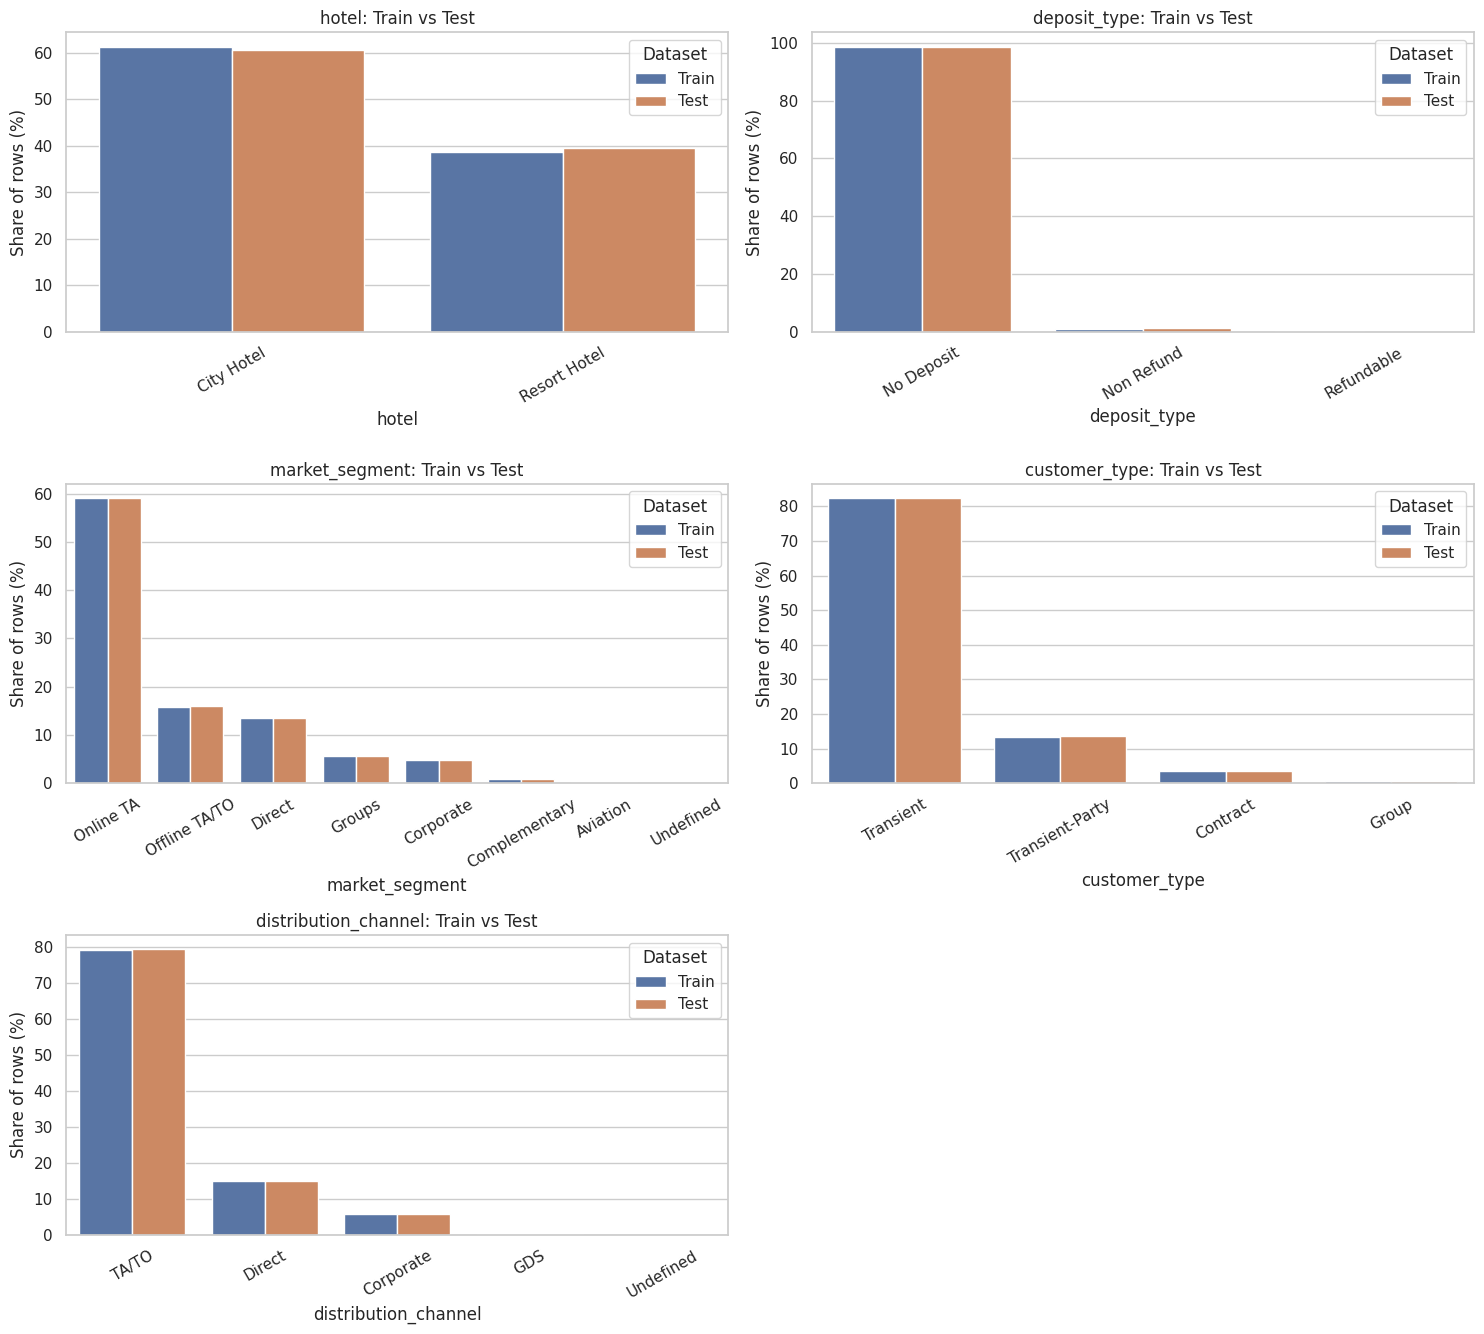

Interpretation: compare the Train and Test bars for each category. Large differences may indicate distribution shift between the two splits.


In [23]:
# 3. Compare proportions of selected categorical features
categorical_features_to_plot = [
    col for col in [
        "hotel", "deposit_type", "market_segment",
        "customer_type", "distribution_channel"
    ]
    if col in X_train.columns
]

if categorical_features_to_plot:
    ncols = 2
    nrows = int(np.ceil(len(categorical_features_to_plot) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(15, 4.5 * nrows))
    axes = np.asarray(axes).reshape(-1)

    for feature, ax in zip(categorical_features_to_plot, axes):
        train_values = X_train[feature].astype("object").where(X_train[feature].notna(), "Missing").astype(str)
        test_values = X_test[feature].astype("object").where(X_test[feature].notna(), "Missing").astype(str)

        combined_counts = pd.concat([train_values, test_values]).value_counts()
        top_categories = combined_counts.head(8).index.tolist()

        plot_rows = []
        for split_name, values in [("Train", train_values), ("Test", test_values)]:
            proportions = values.value_counts(normalize=True).reindex(top_categories, fill_value=0) * 100
            for category, percentage in proportions.items():
                plot_rows.append({"Category": category, "Percentage": percentage, "Dataset": split_name})

        category_plot_df = pd.DataFrame(plot_rows)
        sns.barplot(data=category_plot_df, x="Category", y="Percentage", hue="Dataset", ax=ax)
        ax.set_title(f"{feature}: Train vs Test")
        ax.set_xlabel(feature)
        ax.set_ylabel("Share of rows (%)")
        ax.tick_params(axis="x", rotation=30)

    for ax in axes[len(categorical_features_to_plot):]:
        ax.remove()

    plt.tight_layout()
    plt.show()
else:
    print("No selected categorical features are available for plotting.")

print("Interpretation: compare the Train and Test bars for each category. Large differences may indicate distribution shift between the two splits.")

In [24]:
# 3. Preprocessing + Random Forest model

# Numerical features:
# 1) Replace missing values with the median learned from X_train.
# 2) Standardize each numerical feature: z = (x - mean) / standard deviation.
# Because this is inside the Pipeline, fit() learns these statistics from
# the training set only; X_test is transformed using the same train statistics.
numeric_preprocessor = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical features: fill missing values with the most frequent value,
# then convert categories into numeric indicator columns.
# The try/except supports both newer and older scikit-learn versions.
try:
    one_hot_encoder = OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=True
    )
except TypeError:
    one_hot_encoder = OneHotEncoder(
        handle_unknown="ignore",
        sparse=True
    )

categorical_preprocessor = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", one_hot_encoder)
])

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_preprocessor, numeric_features),
        ("cat", categorical_preprocessor, categorical_features)
    ],
    remainder="drop"
)

rf_classifier = RandomForestClassifier(
    n_estimators=300,
    max_features="sqrt",
    min_samples_leaf=2,
    class_weight="balanced_subsample",
    random_state=RANDOM_STATE,
    n_jobs=-1
)

model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", rf_classifier)
])

print("Pipeline is ready.")
print("Numerical preprocessing: median imputation + StandardScaler")
print("Categorical preprocessing: most-frequent imputation + OneHotEncoder")


Pipeline is ready.
Numerical preprocessing: median imputation + StandardScaler
Categorical preprocessing: most-frequent imputation + OneHotEncoder


In [25]:
# 4. Train the model

model.fit(X_train, y_train)

print("Random Forest training completed.")


Random Forest training completed.


,Metric,Score
0,Accuracy,0.8268
1,Precision,0.6462
2,Recall,0.8177
3,F1-score,0.7219
4,ROC-AUC,0.9065



Classification report:
                  precision    recall  f1-score   support

Not canceled (0)       0.92      0.83      0.87     12675
    Canceled (1)       0.65      0.82      0.72      4805

        accuracy                           0.83     17480
       macro avg       0.78      0.82      0.80     17480
    weighted avg       0.85      0.83      0.83     17480



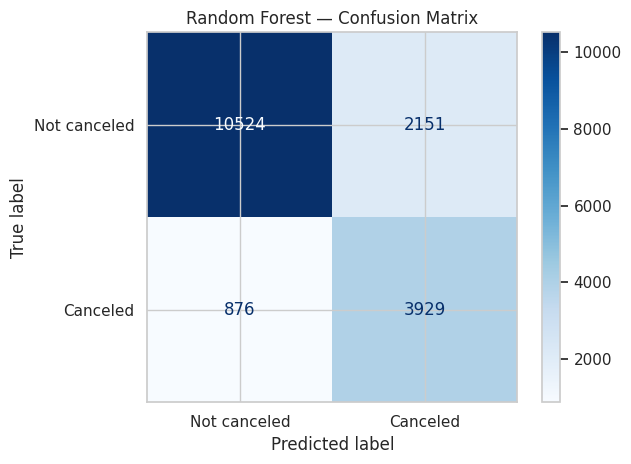

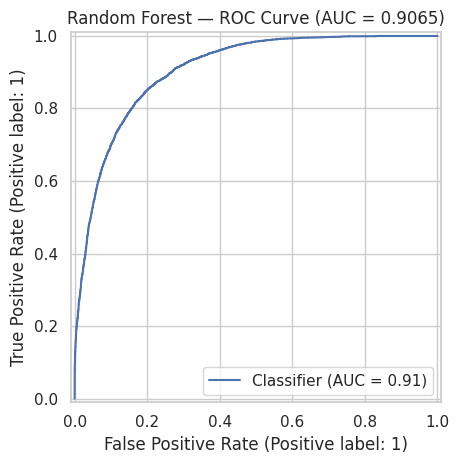

In [26]:
# 5. Evaluate on the held-out test set

y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:, 1]

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, zero_division=0)
recall = recall_score(y_test, y_pred, zero_division=0)
f1 = f1_score(y_test, y_pred, zero_division=0)
roc_auc = roc_auc_score(y_test, y_prob)

metrics_df = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1-score", "ROC-AUC"],
    "Score": [accuracy, precision, recall, f1, roc_auc]
})

display(metrics_df.style.format({"Score": "{:.4f}"}))

print("\nClassification report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=["Not canceled (0)", "Canceled (1)"],
    zero_division=0
))

# Confusion matrix
cm = confusion_matrix(y_test, y_pred, labels=[0, 1])
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Not canceled", "Canceled"]
)
disp.plot(cmap="Blues", values_format="d")
plt.title("Random Forest — Confusion Matrix")
plt.tight_layout()
plt.show()

# ROC curve
RocCurveDisplay.from_predictions(y_test, y_prob)
plt.title(f"Random Forest — ROC Curve (AUC = {roc_auc:.4f})")
plt.tight_layout()
plt.show()


## Visual Analysis — Test Results


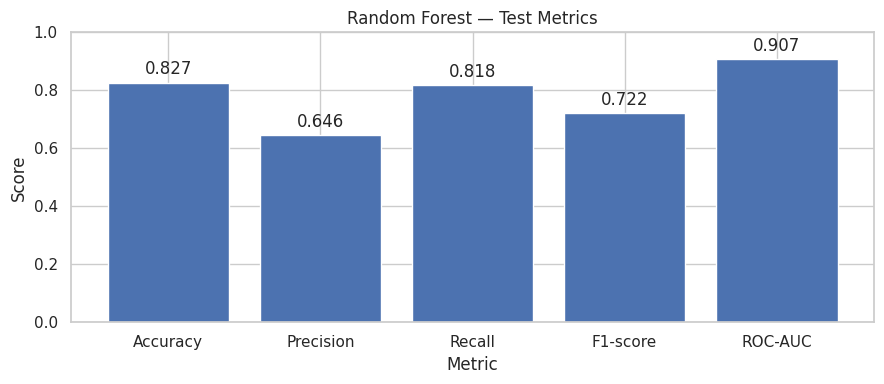

In [27]:
# 1. Visual comparison of evaluation metrics
plt.figure(figsize=(9, 4))
bars = plt.bar(metrics_df["Metric"], metrics_df["Score"])
plt.ylim(0, 1)
plt.title("Random Forest — Test Metrics")
plt.xlabel("Metric")
plt.ylabel("Score")
plt.bar_label(bars, fmt="%.3f", padding=3)
plt.tight_layout()
plt.show()


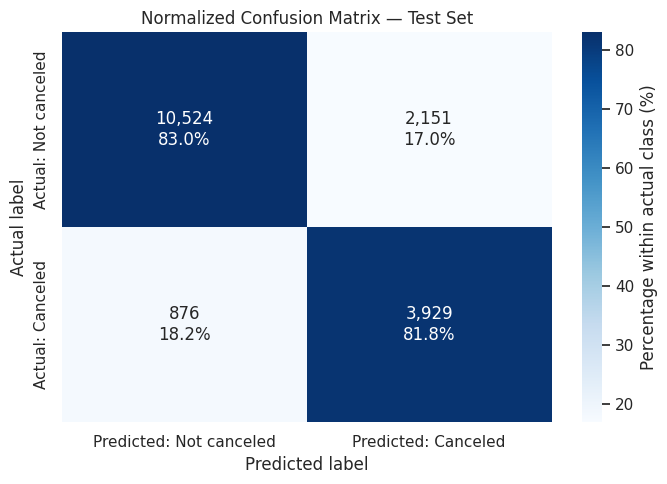

Interpretation:
- False Positive (top-right): model predicts cancellation, but the booking was not canceled.
- False Negative (bottom-left): model misses an actual cancellation.


In [28]:
# 2. Row-normalized confusion matrix (percentages within each actual class)
cm_percent = cm.astype(float) / cm.sum(axis=1, keepdims=True) * 100
cm_labels = np.array([
    [f"{cm[i, j]:,}\n{cm_percent[i, j]:.1f}%" for j in range(cm.shape[1])]
    for i in range(cm.shape[0])
])

plt.figure(figsize=(7, 5))
sns.heatmap(
    cm_percent, annot=cm_labels, fmt="", cmap="Blues",
    xticklabels=["Predicted: Not canceled", "Predicted: Canceled"],
    yticklabels=["Actual: Not canceled", "Actual: Canceled"],
    cbar_kws={"label": "Percentage within actual class (%)"}
)
plt.title("Normalized Confusion Matrix — Test Set")
plt.xlabel("Predicted label")
plt.ylabel("Actual label")
plt.tight_layout()
plt.show()

print("Interpretation:")
print("- False Positive (top-right): model predicts cancellation, but the booking was not canceled.")
print("- False Negative (bottom-left): model misses an actual cancellation.")

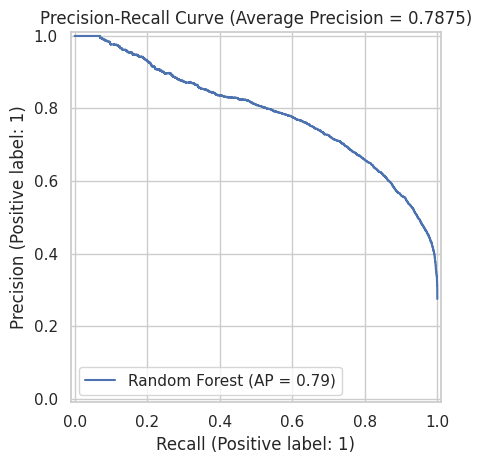

Average Precision on test set: 0.7875


In [29]:
# 3. Precision-Recall curve and Average Precision
from sklearn.metrics import average_precision_score, PrecisionRecallDisplay

average_precision = average_precision_score(y_test, y_prob)
PrecisionRecallDisplay.from_predictions(
    y_test, y_prob, name="Random Forest"
)
plt.title(f"Precision-Recall Curve (Average Precision = {average_precision:.4f})")
plt.tight_layout()
plt.show()
print(f"Average Precision on test set: {average_precision:.4f}")

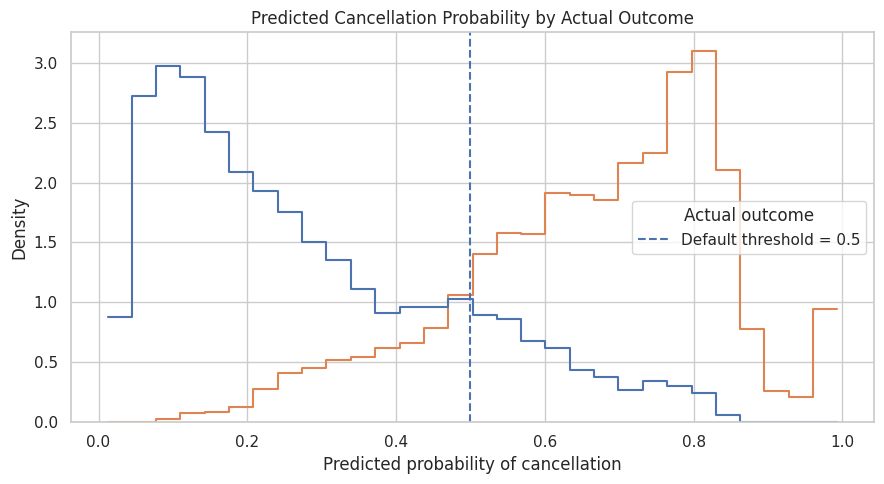

In [30]:
# 4. Predicted cancellation probability by actual class
probability_analysis = pd.DataFrame({
    "Actual outcome": pd.Series(y_test, index=y_test.index).map({
        0: "Not canceled", 1: "Canceled"
    }).values,
    "Predicted cancellation probability": y_prob
})

plt.figure(figsize=(9, 5))
sns.histplot(
    data=probability_analysis,
    x="Predicted cancellation probability",
    hue="Actual outcome",
    bins=30, stat="density", common_norm=False,
    element="step", fill=False
)
plt.axvline(0.5, linestyle="--", linewidth=1.5, label="Default threshold = 0.5")
plt.title("Predicted Cancellation Probability by Actual Outcome")
plt.xlabel("Predicted probability of cancellation")
plt.ylabel("Density")
plt.legend(title="Actual outcome")
plt.tight_layout()
plt.show()

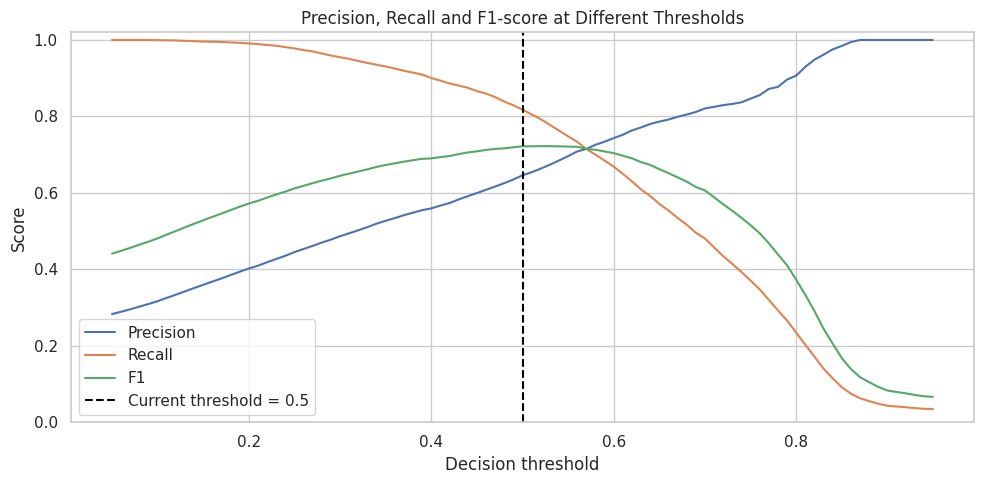

,threshold,precision,recall,f1
45,0.5,0.646217,0.81769,0.721911


Use a separate validation set to choose a threshold; keep the test set for final unbiased evaluation.


In [31]:
# 5. Precision / Recall / F1 trade-off across decision thresholds
# This plot is diagnostic only. Do not tune the final threshold on the test set.
from sklearn.metrics import precision_score, recall_score, f1_score

threshold_grid = np.linspace(0.05, 0.95, 91)
threshold_rows = []
for threshold in threshold_grid:
    threshold_pred = (y_prob >= threshold).astype(int)
    threshold_rows.append({
        "threshold": threshold,
        "precision": precision_score(y_test, threshold_pred, zero_division=0),
        "recall": recall_score(y_test, threshold_pred, zero_division=0),
        "f1": f1_score(y_test, threshold_pred, zero_division=0)
    })
threshold_analysis = pd.DataFrame(threshold_rows)

plt.figure(figsize=(10, 5))
for metric_name in ["precision", "recall", "f1"]:
    plt.plot(
        threshold_analysis["threshold"],
        threshold_analysis[metric_name],
        label=metric_name.capitalize()
    )
plt.axvline(0.5, color="black", linestyle="--", label="Current threshold = 0.5")
plt.ylim(0, 1.02)
plt.xlabel("Decision threshold")
plt.ylabel("Score")
plt.title("Precision, Recall and F1-score at Different Thresholds")
plt.legend()
plt.tight_layout()
plt.show()

display(threshold_analysis.iloc[(threshold_analysis["threshold"] - 0.5).abs().argsort()[:1]])
print("Use a separate validation set to choose a threshold; keep the test set for final unbiased evaluation.")

,Prediction result,Number of bookings
0,Correct,14453
1,False Positive,2151
2,False Negative,876


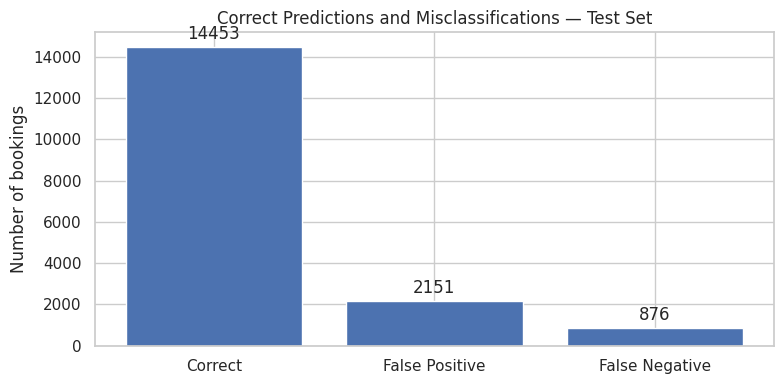

Most confident False Positives (predicted cancellation, actually not canceled):


,hotel,lead_time,deposit_type,market_segment,customer_type,adr,previous_cancellations,actual,predicted,cancellation_probability,error_type
26296,Resort Hotel,122,No Deposit,Online TA,Transient,240.00,0,0,1,0.863442,False Positive
25388,Resort Hotel,202,No Deposit,Online TA,Transient,72.00,0,0,1,0.863435,False Positive
103183,City Hotel,15,No Deposit,Online TA,Transient,76.50,0,0,1,0.859653,False Positive
103047,City Hotel,17,No Deposit,Online TA,Transient,92.67,0,0,1,0.856460,False Positive
91365,City Hotel,121,No Deposit,Online TA,Transient,116.10,0,0,1,0.853685,False Positive


Most confident False Negatives (predicted not canceled, actually canceled):


,hotel,lead_time,deposit_type,market_segment,customer_type,adr,previous_cancellations,actual,predicted,cancellation_probability,error_type
10195,Resort Hotel,0,No Deposit,Direct,Transient-Party,80.0,0,1,0,0.093933,False Negative
44035,City Hotel,83,No Deposit,Offline TA/TO,Transient-Party,112.2,0,1,0,0.095516,False Negative
94308,City Hotel,3,No Deposit,Corporate,Transient,67.0,0,1,0,0.096017,False Negative
18743,Resort Hotel,1,No Deposit,Offline TA/TO,Transient,26.0,0,1,0,0.106887,False Negative
76807,City Hotel,3,No Deposit,Corporate,Transient,65.0,0,1,0,0.119717,False Negative


In [32]:
# 6. Error analysis: False Positives and False Negatives
test_analysis = X_test.copy()
test_analysis["actual"] = y_test
test_analysis["predicted"] = y_pred
test_analysis["cancellation_probability"] = y_prob
test_analysis["error_type"] = np.select(
    [
        (test_analysis["actual"] == 0) & (test_analysis["predicted"] == 1),
        (test_analysis["actual"] == 1) & (test_analysis["predicted"] == 0)
    ],
    ["False Positive", "False Negative"],
    default="Correct"
)

error_counts = (
    test_analysis["error_type"]
    .value_counts()
    .reindex(["Correct", "False Positive", "False Negative"], fill_value=0)
    .rename_axis("Prediction result")
    .reset_index(name="Number of bookings")
)
display(error_counts)

plt.figure(figsize=(8, 4))
bars = plt.bar(error_counts["Prediction result"], error_counts["Number of bookings"])
plt.title("Correct Predictions and Misclassifications — Test Set")
plt.xlabel("")
plt.ylabel("Number of bookings")
plt.bar_label(bars, fmt="%.0f", padding=3)
plt.tight_layout()
plt.show()

# Inspect representative errors together with selected original features.
context_features = [
    c for c in ["hotel", "lead_time", "deposit_type", "market_segment",
               "customer_type", "adr", "previous_cancellations"]
    if c in test_analysis.columns
]
display_columns = context_features + [
    "actual", "predicted", "cancellation_probability", "error_type"
]

false_positives = test_analysis[test_analysis["error_type"] == "False Positive"]
false_negatives = test_analysis[test_analysis["error_type"] == "False Negative"]

print("Most confident False Positives (predicted cancellation, actually not canceled):")
display(false_positives.sort_values("cancellation_probability", ascending=False)
        [display_columns].head(5))

print("Most confident False Negatives (predicted not canceled, actually canceled):")
display(false_negatives.sort_values("cancellation_probability", ascending=True)
        [display_columns].head(5))

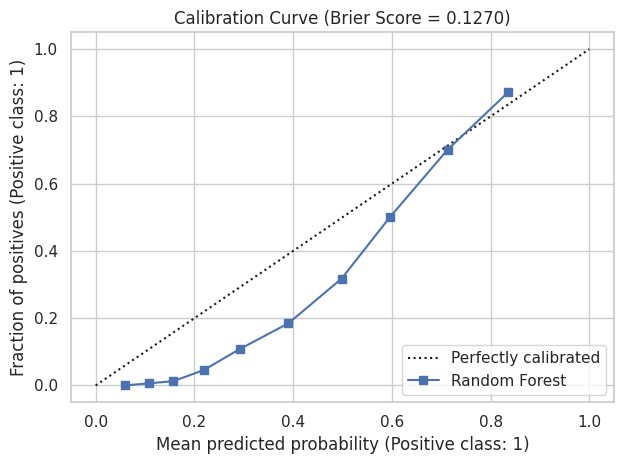

Brier score on test set: 0.1270 (lower is better; 0 is perfect)


In [33]:
# 7. Probability calibration and Brier score
from sklearn.calibration import CalibrationDisplay
from sklearn.metrics import brier_score_loss

brier = brier_score_loss(y_test, y_prob)
CalibrationDisplay.from_predictions(
    y_test, y_prob, n_bins=10, strategy="quantile",
    name="Random Forest"
)
plt.title(f"Calibration Curve (Brier Score = {brier:.4f})")
plt.tight_layout()
plt.show()
print(f"Brier score on test set: {brier:.4f} (lower is better; 0 is perfect)")

,feature,importance
0,num__lead_time,0.109163
1,cat__country_PRT,0.086869
2,num__total_of_special_requests,0.058397
3,num__required_car_parking_spaces,0.057797
4,num__adr,0.049406
5,cat__agent_9,0.035433
6,cat__market_segment_Online TA,0.035173
7,num__arrival_date_week_number,0.028425
8,num__arrival_date_day_of_month,0.026143
9,num__stays_in_week_nights,0.024793


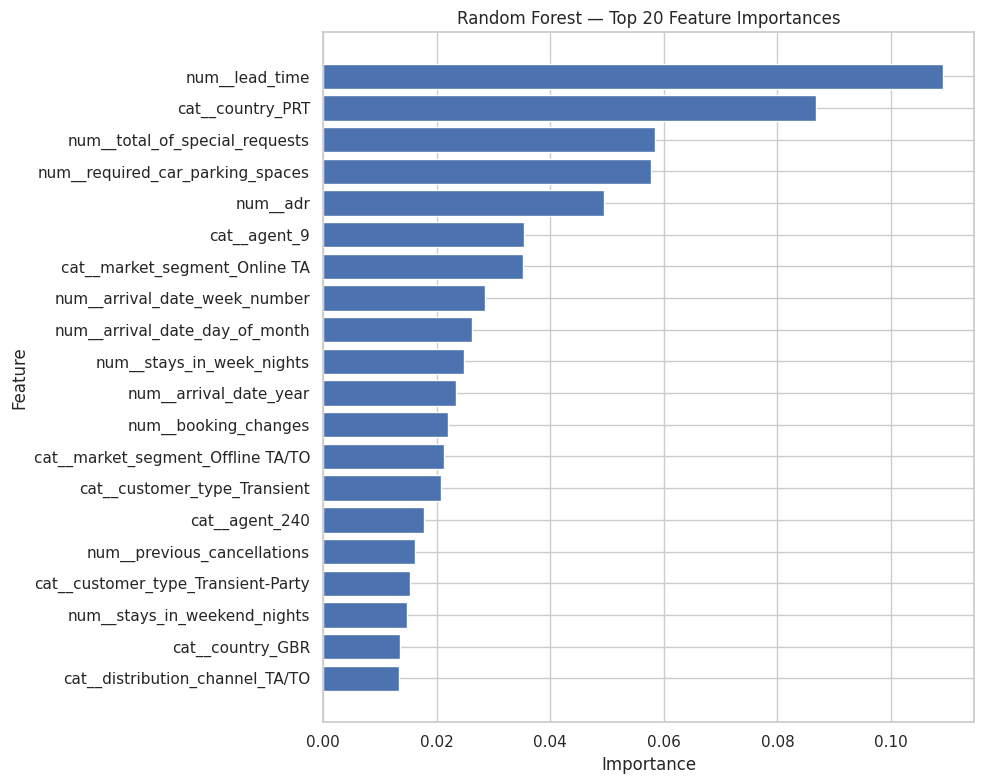

In [34]:
# 6. Feature importance — Top 20 features

# Get the feature names after imputation and One-Hot Encoding.
feature_names = model.named_steps["preprocessor"].get_feature_names_out()
importances = model.named_steps["classifier"].feature_importances_

feature_importance = (
    pd.DataFrame({
        "feature": feature_names,
        "importance": importances
    })
    .sort_values("importance", ascending=False)
    .reset_index(drop=True)
)

top_features = feature_importance.head(20).sort_values("importance")

display(feature_importance.head(20))

plt.figure(figsize=(10, 8))
plt.barh(top_features["feature"], top_features["importance"])
plt.title("Random Forest — Top 20 Feature Importances")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()


## Save the trained model

Sau khi train thành công, cell dưới đây lưu toàn bộ pipeline (preprocessing + Random Forest) để có thể nạp lại và dự đoán dữ liệu mới. Khi dự đoán, dữ liệu đầu vào cần có cùng các cột feature như `X` và không chứa `is_canceled`.


In [35]:
import joblib

MODEL_PATH = "hotel_cancellation_random_forest.joblib"
joblib.dump(model, MODEL_PATH)

print(f"Saved trained model to: {MODEL_PATH}")


Saved trained model to: hotel_cancellation_random_forest.joblib
